<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [25]:
#Importation de la librairie Pandas
import pandas as pd

In [26]:
#Importation de la librairie plotly express
import matplotlib.pyplot as plt

In [27]:
#Importation de la librairie numpy
import numpy as np

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [28]:
#Importation du fichier web.xlsx (préalablement converti en csv)
df_web = pd.read_csv("web.csv", sep=";", encoding="utf-8", header=0)
#Importation du fichier erp.xlsx (préalablement converti en csv)
df_erp = pd.read_csv("erp.csv", sep=";", encoding="utf-8", header=0)
#importation du fichier liaison.xlsx (préalablement converti en csv)
df_liaison = pd.read_csv("liaison.csv", sep=";", encoding="utf-8", header=0)

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [29]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [30]:
#Consulter le nombre de colonnes
print("\nNombre total de colonnes :", len(df_erp.columns))
#La nature des données dans chacune des colonnes
print("\nTypes de données dans chaque colonne :")
print(df_erp.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("\nNombre de valeurs présentes dans chaque colonne :")
print(df_erp.count())


Nombre total de colonnes : 6

Types de données dans chaque colonne :
product_id         int64
onsale_web         int64
price             object
stock_quantity     int64
stock_status      object
purchase_price    object
dtype: object

Nombre de valeurs présentes dans chaque colonne :
product_id        825
onsale_web        825
price             825
stock_quantity    825
stock_status      825
purchase_price    825
dtype: int64


In [31]:
#Afficher les 5 premières lignes de la table
print(df_erp.head())

   product_id  onsale_web price  stock_quantity stock_status purchase_price
0        3847           1  24,2              16      instock          12,88
1        3849           1  34,3              10      instock          17,54
2        3850           1  20,8               0   outofstock          10,64
3        4032           1  14,1              26      instock           6,92
4        4039           1    46               3   outofstock          23,77


In [32]:
#Vérifier si il y a les lignes en doublons dans la colonne product_id
count_unique = df_erp['product_id'].nunique()
total_count = df_erp['product_id'].count()

print(f"Nombre de valeurs distinctes dans 'product_id' : {count_unique}")
print(f"Nombre total de 'product_id' : {total_count}")

if count_unique < total_count:
    print("Il y a des doublons dans la colonne 'product_id'.")
else:
    print("Il n'y a pas de doublons dans la colonne 'product_id'.")

Nombre de valeurs distinctes dans 'product_id' : 825
Nombre total de 'product_id' : 825
Il n'y a pas de doublons dans la colonne 'product_id'.


In [33]:
#Afficher les valeurs distinctes de la colonne stock_status
valeurs_distinctes = df_erp['stock_status'].unique()
print("Valeurs distinctes dans la colonne 'stock_status' :")
print(valeurs_distinctes)
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
#Ces valeurs sont liées à stock_quantity

Valeurs distinctes dans la colonne 'stock_status' :
['instock' 'outofstock']


In [34]:
#Création d'une colonne "stock_status_2
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#si la valeur de la colonne "stock_quantity" est nulle renseigner "outofstock" sinon mettre "instock"
df_erp['stock_status_2'] = np.where(df_erp['stock_quantity'].isnull() | (df_erp['stock_quantity'] == 0), 
                                     'outofstock', 
                                     'instock')

In [35]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [36]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset
df_erp['stock_status_difference'] = (df_erp['stock_status'] == df_erp['stock_status_2']).astype(int)

# Calculer la somme des valeurs de _stock_status_difference égales à 1
somme_difference = df_erp['stock_status_difference'].sum()

print(f"La somme de 'stock_status_difference' quand c'est égal à 1 est : {somme_difference}")

La somme de 'stock_status_difference' quand c'est égal à 1 est : 821


In [37]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
# Filtrer les lignes où _stock_status_difference est égal à 0
lignes_avec_ecart = df_erp[df_erp['stock_status_difference'] == 0]

# Afficher les lignes avec un écart
print("Lignes avec écart entre stock_status et stock_status_2 :")
print(lignes_avec_ecart)

Lignes avec écart entre stock_status et stock_status_2 :
     product_id  onsale_web price  stock_quantity stock_status purchase_price  \
4          4039           1    46               3   outofstock          23,77   
398        4885           1  18,7               0      instock           9,66   
449        4973           0    10             -10   outofstock           4,96   
573        5700           1  44,5              -1   outofstock           22,3   

    stock_status_2  stock_status_difference  
4          instock                        0  
398     outofstock                        0  
449        instock                        0  
573        instock                        0  


In [38]:
#Corriger la ou les données incohérentes
# Modifier la valeur de stock_status pour la ligne 4
df_erp.at[4, 'stock_status'] = 'instock'

# Modifier la valeur de stock_status pour la ligne 398
df_erp.at[398, 'stock_status'] = 'outofstock'

# Modifier la valeur de stock_quantity pour la ligne 449
df_erp.at[449, 'stock_quantity'] = 0

# Modifier la valeur de stock_quantity pour la ligne 573
df_erp.at[573, 'stock_quantity'] = 0

# Verification en utilisant le même code que plus haut pour afficher les problemes
df_erp['stock_status_2'] = np.where(df_erp['stock_quantity'].isnull() | (df_erp['stock_quantity'] == 0), 
                                     'outofstock', 
                                     'instock')

df_erp['stock_status_difference'] = (df_erp['stock_status'] == df_erp['stock_status_2']).astype(int)

# Calculer la somme des valeurs de _stock_status_difference égales à 1
somme_difference = df_erp['stock_status_difference'].sum()

print(f"La somme de 'stock_status_difference' quand c'est égal à 1 est : {somme_difference}")

La somme de 'stock_status_difference' quand c'est égal à 1 est : 825


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [39]:
###############
## LES PRIX  ##
###############

df_erp['price'] = df_erp['price'].astype(str).str.replace(',', '.', regex=False)
df_erp['price'] = pd.to_numeric(df_erp['price'])

#Vérification des prix: Y a t-il des prix non renseignés, négatif ou nul?
prix_non_renseignes = df_erp['price'].isnull()  # Vérifier les valeurs manquantes
print(prix_non_renseignes.sum())
prix_negatifs = df_erp['price'] < 0  # Vérifier les prix négatifs
print(prix_negatifs.sum())
prix_nuls = df_erp['price'] == 0  # Vérifier les prix nuls
print(prix_nuls.sum())

#Afficher le ou les prix non renseignés dans la colonne "price"
nombre_prix_non_renseigne = df_erp['price'].isnull().sum()
print("Nombre d'articles avec un prix non renseigné: {}".format(nombre_prix_non_renseigne)) #Saisir l'instruction manquante dans la fonction format

#Afficher le prix minimum de la colonne "price"
prix_minimum = df_erp['price'].min()
print("Le prix minimum dans la colonne 'price' est : {}".format(prix_minimum))

#Afficher le prix maximum de la colonne "price"
prix_maximum = df_erp['price'].max()
print("Le prix maximum dans la colonne 'price' est : {}".format(prix_maximum))

#Afficher les prix inférieurs à 0 (qu'est ce qu'il faut en faire ?)
prix_inferieurs_a_zero = df_erp[df_erp['price'] < 0]
print("Lignes avec des prix inférieurs à 0 :")
print(prix_inferieurs_a_zero[['price']])

0
3
0
Nombre d'articles avec un prix non renseigné: 0
Le prix minimum dans la colonne 'price' est : -20.0
Le prix maximum dans la colonne 'price' est : 225.0
Lignes avec des prix inférieurs à 0 :
     price
151  -20.0
469   -8.0
739   -9.1


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [40]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
quantite_minimum = df_erp['stock_quantity'].min()
print("La quantité minimum dans la colonne 'stock_quantity' est : {}".format(quantite_minimum))

#Afficher la quantité maximum de la colonne "stock_quantity"
quantite_maximum = df_erp['stock_quantity'].max()
print("La quantité maximum dans la colonne 'stock_quantity' est : {}".format(quantite_maximum))

#Afficher les stocks inférieurs à 0 (qu'est ce qu'il faut en faire ?)
# /!\ Passage des valeurs négatives à 0

La quantité minimum dans la colonne 'stock_quantity' est : 0
La quantité maximum dans la colonne 'stock_quantity' est : 145


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [41]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient? Que signifient-elles?
valeurs_distinctes_onsale = df_erp['onsale_web'].unique()

print("Valeurs distinctes dans la colonne 'onsale_web' :")
print(valeurs_distinctes_onsale)

# Ces valeurs signifient si le produit est en vente sur le site web

Valeurs distinctes dans la colonne 'onsale_web' :
[1 0]


In [42]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
df_erp = df_erp.drop(columns=['stock_status_2'])

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [43]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
prix_non_renseignes = df_erp[df_erp['purchase_price'].isnull()]
print("Lignes avec des prix non renseignés dans 'purchase_price' :")
print(prix_non_renseignes[['purchase_price']])

#Afficher le prix minimum de la colonne "purchase_price"
prix_minimum = df_erp['purchase_price'].min()
print("Le prix minimum dans la colonne 'purchase_price' est : {}".format(prix_minimum))

#Afficher le prix maximum de la colonne "purchase_price"
prix_maximum = df_erp['purchase_price'].max()
print("Le prix maximum dans la colonne 'purchase_price' est : {}".format(prix_maximum))

Lignes avec des prix non renseignés dans 'purchase_price' :
Empty DataFrame
Columns: [purchase_price]
Index: []
Le prix minimum dans la colonne 'purchase_price' est : 10,01
Le prix maximum dans la colonne 'purchase_price' est : 99


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [44]:
df_web = df_web[df_web['post_type'] == 'product']

In [45]:
#Dimension du dataset
#Nombre d'observations
print("Le tableau comporte {} observation(s) ou article(s)".format(df_web.shape[0]))
#Nombre de caractéristiques
print("Le tableau comporte {} caractéristique(s)".format(df_web.shape[1]))

Le tableau comporte 716 observation(s) ou article(s)
Le tableau comporte 29 caractéristique(s)


In [46]:
#Consulter le nombre de colonnes
print("\nNombre total de colonnes :", len(df_web.columns))
#La nature des données dans chacune des colonnes
print("\nTypes de données dans chaque colonne :")
print(df_web.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("\nNombre de valeurs présentes dans chaque colonne :")
print(df_web.count())


Nombre total de colonnes : 29

Types de données dans chaque colonne :
sku                       object
virtual                    int64
downloadable               int64
rating_count               int64
average_rating           float64
total_sales              float64
tax_status                object
tax_class                float64
post_author              float64
post_date                 object
post_date_gmt             object
post_content             float64
product_type              object
post_title                object
post_excerpt              object
post_status               object
comment_status            object
ping_status               object
post_password            float64
post_name                 object
post_modified             object
post_modified_gmt         object
post_content_filtered    float64
post_parent              float64
guid                      object
menu_order               float64
post_type                 object
post_mime_type            object
comme

In [47]:
# Les colonnes à supprimer
# virtual, downloadable, rating_count, average_rating, tax_class, post_content, ping_status, post_password, post_content_filtered, post_parent, menu_order, comment_count

In [48]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web = df_web.drop(columns=['virtual','downloadable','rating_count','average_rating','tax_class','post_content','ping_status','post_password','post_content_filtered','post_parent','menu_order','comment_count'])

In [49]:
#Visualisation des valeurs de la colonne sku
skus_uniques = df_web["sku"].unique()
print(skus_uniques)

#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?
skus_erronés = [sku for sku in skus_uniques 
                if pd.notna(sku) and 
                (not str(sku).startswith('1') or len(str(sku)) != 5)]

print(skus_erronés)

['14692' '15328' '16515' '16585' '12869' '15575' '14338' '16560' '15361'
 '15022' '16342' '16029' '13754' '14680' '9636' '13849' '15481' '15448'
 '15441' '804' '16071' '12882' '16053' '13766' '12640' '15476' '16038'
 '14864' '16044' '15324' '15413' '13809' '15895' '15849' '12315' '15934'
 '15148' '15781' '15106' '15490' '14507' '16307' '13736' '16037' '12587'
 '16305' '16131' '13435' '15758' '14509' '14768' '16505' '15871' '11602'
 '13127' '13520' '13032' '15436' '15910' '16263' '15138' '16580' '13905'
 '13557' '14975' '15341' '15415' '16065' '15479' '16151' '15127' '15140'
 '15779' '9937' '15281' '15315' '15668' '15161' '15792' '15921' '15870'
 '15690' '15561' '15539' '16320' '3509' '2534' '11586' '14819' '15705'
 '15254' '15554' '14451' '16274' '14696' '14573' '16238' '15834' '15141'
 '15038' '15238' '16586' '15664' '14527' '15707' '15269' '14845' '14700'
 '15440' '15759' '11277' '15676' '15731' '16525' '15785' '14699' '15718'
 '14372' '15881' '15426' '16023' '14661' '15675' '15351' 

In [50]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les?
df_web_codification_erronée =  df_web[df_web["sku"].isin(skus_erronés)]
print(df_web_codification_erronée)

                      sku  total_sales tax_status  post_author  \
33                   9636          0.0    taxable          2.0   
48                    804          3.0    taxable          2.0   
167                  9937          2.0    taxable          2.0   
194                  3509          5.0    taxable          2.0   
195                  2534          4.0    taxable          2.0   
272               13127-1          4.0    taxable          2.0   
370                   791          1.0    taxable          2.0   
420                  7086          5.0    taxable          2.0   
445                  7819          4.0    taxable          2.0   
450                  4679          0.0    taxable          2.0   
505                  2361          4.0    taxable          2.0   
536                   793          1.0    taxable          2.0   
538                   812          3.0    taxable          2.0   
547                  3383          3.0    taxable          2.0   
548       

In [51]:
#Identifier les lignes sans code articles
df_sans_codification = df_web[df_web["sku"].isna()]
print(df_sans_codification)

      sku  total_sales tax_status  post_author            post_date  \
1084  NaN        -56.0    taxable          2.0  2018-08-08 11:23:43   
1087  NaN        -17.0    taxable          2.0  2018-07-31 12:07:23   

            post_date_gmt product_type  \
1084  2018-08-08 09:23:43          Vin   
1087  2018-07-31 10:07:23          Vin   

                                           post_title  \
1084  Pierre Jean Villa Condrieu Jardin Suspendu 2018   
1087       Pierre Jean Villa Côte Rôtie Fongeant 2017   

                                           post_excerpt post_status  \
1084  <span id="u1194-83">Le nez séduit par ses parf...     publish   
1087  Fongeant 2017 explose sur un fruit brillant, p...     publish   

     comment_status                                   post_name  \
1084         closed    pierre-jean-villa-condrieu-suspendu-2018   
1087         closed  pierre-jean-villa-cote-rotie-fongeant-2017   

            post_modified    post_modified_gmt  \
1084  2019-11-02 13:2

In [52]:
#Pour les codes articles identifiés, réalisé une analyse et définissez l'action à entreprendre
df_web = df_web[df_web["sku"].notna()]
print(df_web)

        sku  total_sales tax_status  post_author            post_date  \
2     14692          5.0    taxable          2.0  2019-03-19 10:06:47   
4     15328          2.0    taxable          2.0  2019-03-27 18:05:09   
6     16515         10.0    taxable          2.0  2018-06-02 09:31:31   
11    16585         15.0    taxable          2.0  2018-02-16 14:03:16   
14    12869          7.0    taxable          2.0  2019-03-28 14:29:35   
...     ...          ...        ...          ...                  ...   
1503  13074          4.0    taxable          2.0  2018-02-12 14:25:28   
1505  16322          0.0    taxable          2.0  2018-02-15 13:51:32   
1507  12365         10.0    taxable          2.0  2019-01-29 15:53:05   
1508  16326          5.0    taxable          2.0  2019-04-18 11:32:46   
1509  15662         15.0    taxable          2.0  2018-02-27 10:13:03   

            post_date_gmt product_type  \
2     2019-03-19 09:06:47          Vin   
4     2019-03-27 17:05:09          Vin 

In [53]:
#La clé pour chaque ligne est-elle uniques? ou autrement dit, y a-t-il des doublons?
nombre_total_skus = len(df_web)
nombre_unique_skus = df_web["sku"].nunique()
nombre_doublons = nombre_total_skus - nombre_unique_skus

print(f"Nombre total de clés : {nombre_total_skus}")
print(f"Nombre de clés uniques : {nombre_unique_skus}")

if nombre_doublons > 0:
    print(f"Il y a des doublons : {nombre_doublons} doublons trouvés.")
else:
    print("Il n'y a pas de doublons.")

Nombre total de clés : 714
Nombre de clés uniques : 714
Il n'y a pas de doublons.


In [54]:
#Les lignes sans code article semble être toutes non renseignés
#Pour s'en assurer réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
print(df_sans_codification)
#2 - utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeur reseigner dans chacune des colonnes
df_sans_codification.info()
#3 - Que constatez-vous?
# 2 lignes dont le code article est manquant possède des infos

      sku  total_sales tax_status  post_author            post_date  \
1084  NaN        -56.0    taxable          2.0  2018-08-08 11:23:43   
1087  NaN        -17.0    taxable          2.0  2018-07-31 12:07:23   

            post_date_gmt product_type  \
1084  2018-08-08 09:23:43          Vin   
1087  2018-07-31 10:07:23          Vin   

                                           post_title  \
1084  Pierre Jean Villa Condrieu Jardin Suspendu 2018   
1087       Pierre Jean Villa Côte Rôtie Fongeant 2017   

                                           post_excerpt post_status  \
1084  <span id="u1194-83">Le nez séduit par ses parf...     publish   
1087  Fongeant 2017 explose sur un fruit brillant, p...     publish   

     comment_status                                   post_name  \
1084         closed    pierre-jean-villa-condrieu-suspendu-2018   
1087         closed  pierre-jean-villa-cote-rotie-fongeant-2017   

            post_modified    post_modified_gmt  \
1084  2019-11-02 13:2

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [55]:
#Dimension du dataset
#Nombre d'observations
print("Le tableau comporte {} observation(s) ou article(s)".format(df_liaison.shape[0]))
#Nombre de caractéristiques
print("Le tableau comporte {} caractéristique(s)".format(df_liaison.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 caractéristique(s)


In [56]:
#Consulter le nombre de colonnes
print("\nNombre total de colonnes :", len(df_liaison.columns))
#La nature des données dans chacune des colonnes
print("\nTypes de données dans chaque colonne :")
print(df_liaison.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("\nNombre de valeurs présentes dans chaque colonne :")
print(df_liaison.count())


Nombre total de colonnes : 2

Types de données dans chaque colonne :
id_web        object
product_id     int64
dtype: object

Nombre de valeurs présentes dans chaque colonne :
id_web        734
product_id    825
dtype: int64


In [57]:
#Les valeurs de la colonne "product_id" sont elles toutes uniques?
produits_uniques = df_liaison['product_id'].is_unique  # Renvoie True si toutes les valeurs sont uniques
print(f"Toutes les valeurs de 'product_id' sont-elles uniques ? {produits_uniques}")

Toutes les valeurs de 'product_id' sont-elles uniques ? True


In [58]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
id_web_uniques = df_liaison['id_web'].is_unique  # Renvoie True si toutes les valeurs sont uniques
print(f"Toutes les valeurs de 'id_web' sont-elles uniques ? {id_web_uniques}")

Toutes les valeurs de 'id_web' sont-elles uniques ? False


In [59]:
#Avons-nous des articles sans correspondances?
produits_non_renseignes = df_liaison['id_web'].isnull()  # Vérifier les valeurs manquantes
print(produits_non_renseignes.sum())

91


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [60]:
#Fusion des fichiers df_erp et df_liaison
df_merge = pd.merge(df_erp, df_liaison, on="product_id", how="inner")

In [61]:
#Y a t-il des lignes ne "matchant" entre les 2 fichiers?
df_merge2 = pd.merge(df_erp, df_liaison, on="product_id", how="outer", indicator=True)
non_matches_erp = df_merge2[df_merge2["_merge"] == "left_only"]
non_matches_liaison = df_merge2[df_merge2["_merge"] == "right_only"]
print(f"Lignes de df_erp sans match : {non_matches_erp.shape[0]}")
print(f"Lignes de df_liaison sans match : {non_matches_liaison.shape[0]}")

Lignes de df_erp sans match : 0
Lignes de df_liaison sans match : 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [62]:
df_merge["product_id"] = df_merge["product_id"].astype(str)
df_web["sku"] = df_web["sku"].astype(str)

In [63]:
#Fusionnez les datasets df_merge et df_web
df_final = pd.merge(df_merge, df_web, left_on="id_web", right_on="sku", how="inner")

In [64]:
#Avons-nous des lignes sans correspondances?
df_merge3 = pd.merge(df_merge, df_web, left_on="product_id", right_on="sku", how="outer", indicator=True)

# Lignes de df_merge sans correspondance dans df_web
non_matches_merge = df_merge2[df_merge2["_merge"] == "left_only"]
print(f"Lignes de df_merge sans match : {non_matches_merge.shape[0]}")

# Lignes de df_web sans correspondance dans df_merge
non_matches_web = df_merge2[df_merge2["_merge"] == "right_only"]
print(f"Lignes de df_web sans match : {non_matches_web.shape[0]}")

Lignes de df_merge sans match : 0
Lignes de df_web sans match : 0


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univarié des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

In [65]:
df_final['price'] = pd.to_numeric(df_final['price'], errors='coerce')

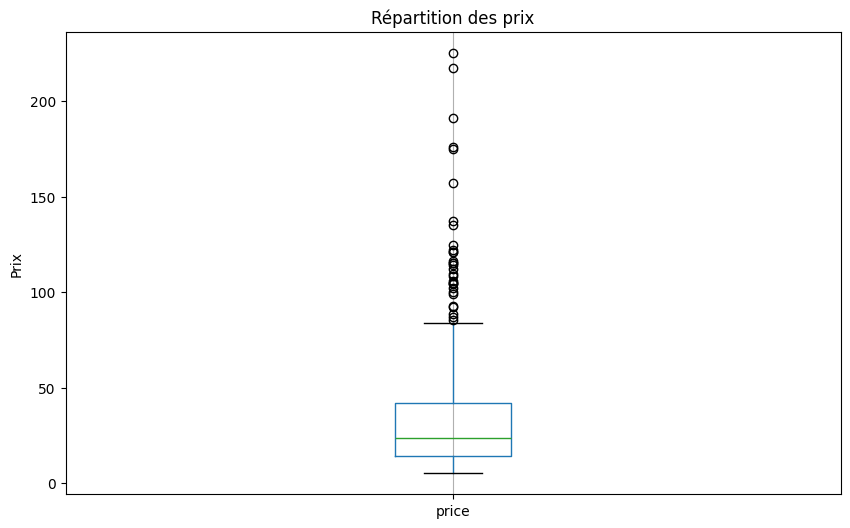

In [66]:
#Création d'une Boite à moustache de la répartition des prix grâce à Pandas
plt.figure(figsize=(10, 6))
df_final.boxplot(column='price')
plt.title('Répartition des prix')
plt.ylabel('Prix')
plt.grid(axis='y')
plt.show()

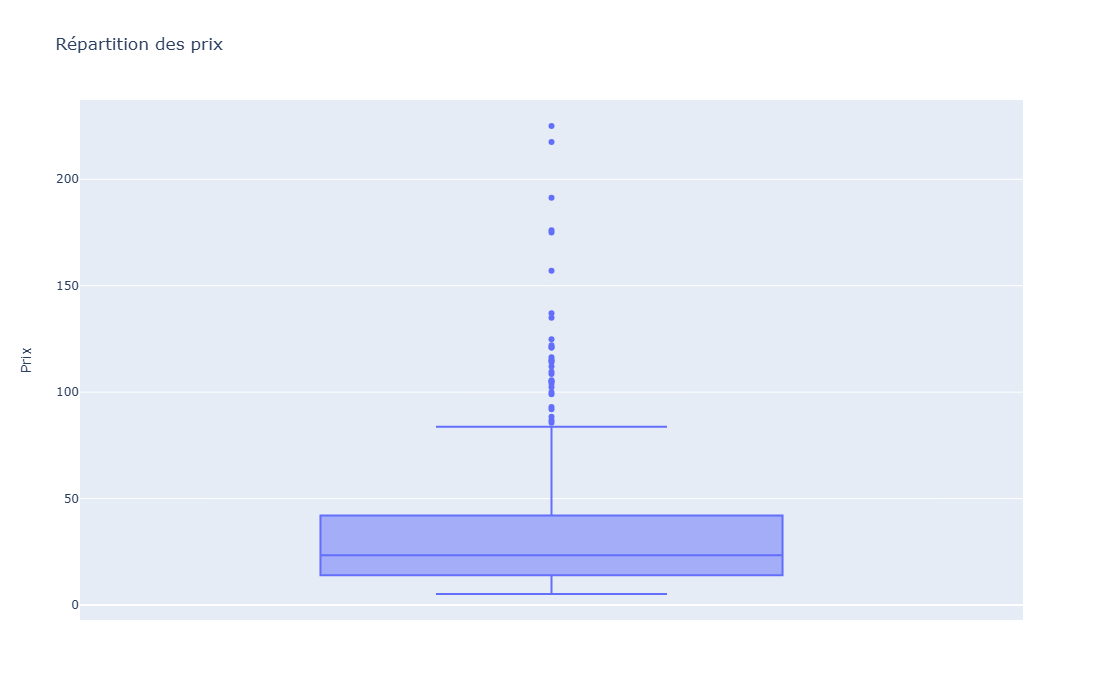

In [69]:
#Autre méthode avec plotly express
import plotly.express as px

fig = px.box(df_final, y='price', title='Répartition des prix')
fig.update_layout(
    yaxis_title='Prix',
    height=700  # Tu peux adapter la valeur (ex: 500, 700, etc.)
)
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utisation de méthodes statistique</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [70]:
#Calculer la moyenne du prix
moyenne_price = df_final['price'].mean()
print("La moyenne de la variable 'price' est :", moyenne_price)

#Calculer l'écart-type du prix
ecart_type_price = df_final['price'].std()
print("L'écart-type de la variable 'price' est :", ecart_type_price)

#Calculer le Z-score
df_final['z_score'] = (df_final['price'] - moyenne_price) / ecart_type_price
print(df_final[['price', 'z_score']])

La moyenne de la variable 'price' est : 32.33368347338936
L'écart-type de la variable 'price' est : 27.5963324191972
     price   z_score
0     24.2 -0.294738
1     34.3  0.071253
2     20.8 -0.417943
3     14.1 -0.660729
4     46.0  0.495222
..     ...       ...
709    8.4 -0.867278
710   27.5 -0.175157
711   69.0  1.328666
712   54.8  0.814105
713   16.3 -0.581008

[714 rows x 2 columns]


In [71]:
#Quel est le seuil prix dont z-score est supérieur à 3?
seuil_theorique = moyenne_price + 3 * ecart_type_price
print("'price' doit être supérieur à", seuil_theorique, "pour avoir un z-score supérieur à 3")

'price' doit être supérieur à 115.12268073098096 pour avoir un z-score supérieur à 3


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'interval interquartile</h3>
</div>

In [72]:
#Utilisation de la fonction describe de Pandas pour l'etude des mesures de dispersions
print(df_final['price'].describe())

count    714.000000
mean      32.333683
std       27.596332
min        5.200000
25%       14.062500
50%       23.450000
75%       42.075000
max      225.000000
Name: price, dtype: float64


In [73]:
#Définissez un seuil pour les articles "outliers" en prix
Q1 = df_final['price'].quantile(0.25)
Q3 = df_final['price'].quantile(0.75)
IQR = Q3 - Q1

# Seuils théoriques des outliers
seuil_bas = Q1 - 1.5 * IQR
seuil_haut = Q3 + 3 * IQR

print(f"Seuil inférieur (outliers bas) : {seuil_bas}")
print(f"Seuil supérieur (outliers hauts) : {seuil_haut}")

Seuil inférieur (outliers bas) : -27.956250000000004
Seuil supérieur (outliers hauts) : 126.11250000000001


In [74]:
#Définissez le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
# On identifie les outliers
outliers_iqr = df_final[(df_final['price'] < seuil_bas) | (df_final['price'] > seuil_haut)]

# On calcule le nombre d'outliers
nb_outliers = outliers_iqr.shape[0]

# Proportion par rapport à l'ensemble
nb_total = df_final.shape[0]
proportion = nb_outliers / nb_total

print(f"Nombre d'articles outliers : {nb_outliers}")
print(f"Proportion des outliers dans le catalogue : {proportion:.2%}")

Nombre d'articles outliers : 8
Proportion des outliers dans le catalogue : 1.12%


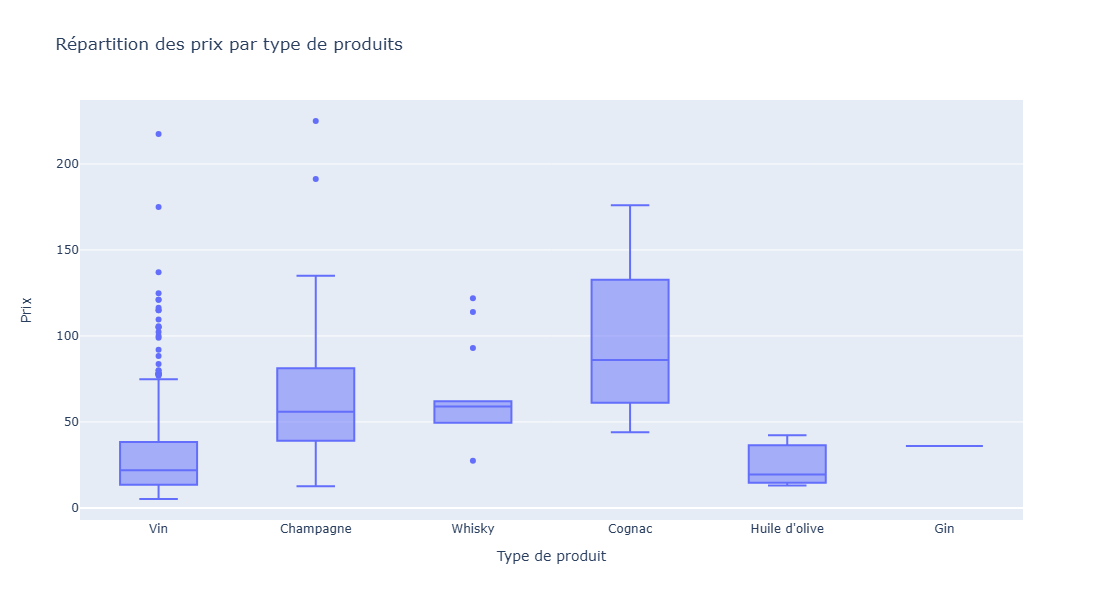

In [75]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
fig = px.box(df_final, x='product_type', y='price', title='Répartition des prix par type de produits')
fig.update_layout(xaxis_title='Type de produit', yaxis_title='Prix', height=600)
fig.show()

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univarié du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivarié  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [76]:
##############################
# Calculer le CA sur site web #
##############################

#Créez une colonne calculant le CA par article
df_final['ca_par_article'] = df_final['price'] * df_final['total_sales']
print(df_final[['product_id', 'price', 'total_sales', 'ca_par_article']].head())

#Calculez la somme de la colonne "ca_par_article"
somme_CA_par_article = df_final['ca_par_article'].sum()
print(f"La somme du chiffre d'affaires (CA) est : {somme_CA_par_article}")

  product_id  price  total_sales  ca_par_article
0       3847   24.2          6.0           145.2
1       3849   34.3          9.0           308.7
2       3850   20.8          0.0             0.0
3       4032   14.1         12.0           169.2
4       4039   46.0          3.0           138.0
La somme du chiffre d'affaires (CA) est : 143680.09999999998


   product_type                                         post_title product_id  \
0     Champagne     Champagne Egly-Ouriet Grand Cru Millésimé 2008       4352   
1     Champagne  Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...       5892   
2     Champagne          Champagne Egly-Ouriet Grand Cru Brut Rosé       4353   
3           Vin              Agnès Levet Côte Rôtie Améthyste 2017       5826   
4           Vin  Domaine des Comtes Lafon Volnay 1er Cru Santen...       6212   
5     Champagne  Champagne Agrapart &amp; Fils Minéral Extra Br...       5026   
6           Vin  Domaine des Comtes Lafon Volnay 1er Cru Santen...       5008   
7           Vin                Camille Giroud Clos de Vougeot 2016       5767   
8     Champagne             Champagne Gosset Célébris Vintage 2007       6126   
9     Champagne  Champagne Agrapart &amp; Fils L'Avizoise Extra...       5025   
10          Vin  David Duband Chambolle-Musigny 1er Cru Les Sen...       6201   
11       Cognac  Cognac Frap

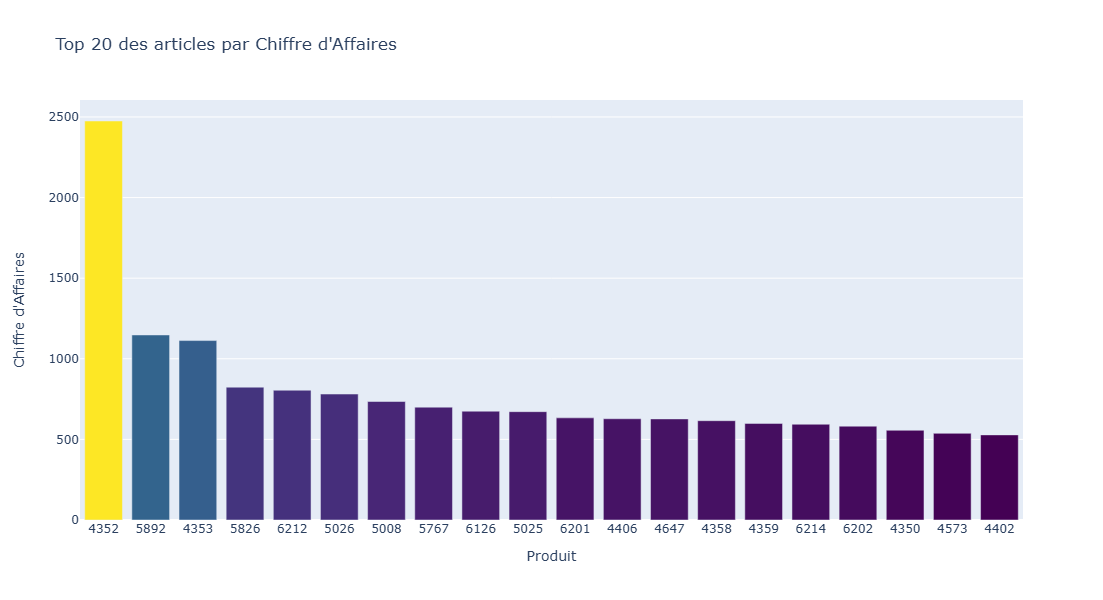

In [82]:
###############################
# Palmares des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_final_décroissant_ca = df_final.sort_values(by='ca_par_article', ascending=False)

#Réinitialiser l'index du dataset par un reset_index
df_final_reset = df_final_décroissant_ca.reset_index(drop=True)

#Afficher les 20 premier articles en CA
top_20_CA = df_final_reset[['product_type','post_title','product_id', 'ca_par_article']].head(20)
print(top_20_CA)

#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(top_20_CA, 
             x='product_id', 
             y='ca_par_article', 
             title='Top 20 des articles par Chiffre d\'Affaires',
             labels={'product_id': 'ID Produit', 'CA': 'Chiffre d\'Affaires'},
             color='ca_par_article', 
             color_continuous_scale='Viridis',
             hover_data=['post_title'])

fig.update_traces(
    hovertemplate="<b>ID Produit</b>: %{x}<br>" +
                  "<b>Nom de l'article</b>: %{customdata[0]}<extra></extra><br>" +
                  "<b>Chiffre d'Affaires</b>: %{y:.2f}<br>",
    customdata=top_20_CA[['post_title']] 
)

# Afficher le graphique
fig.update_layout(
    xaxis_title='Produit',
    yaxis_title='Chiffre d\'Affaires',
    height=600,
    coloraxis_showscale=False
)

fig.show()

In [90]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
ca_total = df_final['ca_par_article'].sum()
df_final['part_CA'] = (df_final['ca_par_article'] / ca_total) *100 # En %
print(df_final[['product_id', 'ca_par_article', 'part_CA']].head())

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_final = df_final.sort_values(by='ca_par_article', ascending=False)
df_final['part_CA_cum'] = df_final['part_CA'].cumsum()
print(df_final[['product_id', 'ca_par_article', 'part_CA', 'part_CA_cum']].head())

#Grâce au deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
articles_80_CA = df_final[df_final['part_CA_cum'] <= 80]
nb_articles_80_CA = articles_80_CA.shape[0]
print(f"Nombre d'articles représentant 80% du CA : {nb_articles_80_CA}")

#Afficher la proportion que représentent ce groupe d'articles dans le catalogue entier du site web
nb_total_articles = df_final.shape[0]
proportion_articles_80_CA = round((nb_articles_80_CA / nb_total_articles) *100,2)
print(f"Proportion des articles responsables de 80% du CA : {proportion_articles_80_CA}%")

    product_id  ca_par_article   part_CA
365       4867           356.4  0.248051
122       4203           267.3  0.186038
175       4275           357.6  0.248886
321       4726           279.4  0.194460
265       4647           627.0  0.436386
    product_id  ca_par_article   part_CA  part_CA_cum
199       4352          2475.0  1.722577     1.722577
587       5892          1147.8  0.798858     2.521435
200       4353          1113.0  0.774638     3.296072
582       5826           824.0  0.573496     3.869569
653       6212           805.0  0.560272     4.429841
Nombre d'articles représentant 80% du CA : 434
Proportion des articles responsables de 80% du CA : 60.78%


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en Quantités</h3>
</div>

   product_type                                         post_title product_id  \
0           Vin  Château De La Selve IGP Coteaux de l'Ardèche M...       4867   
1           Vin  Mas Laval IGP Pays d'Hérault Les Pampres Blanc...       4203   
2           Vin              I Fabbri Chianti Classico Lamole 2017       4275   
3           Vin           François Baur Pinot Noir Schlittweg 2017       4726   
4           Vin  Bernard Baudry Chinon Rouge La Croix Boissée 2017       4647   
5           Vin  Moulin de Gassac IGP Pays d'Hérault Guilhem Bl...       6129   
6           Vin              Agnès Levet Côte Rôtie Améthyste 2017       5826   
7           Vin  Xavier Frissant Touraine Amboise Chenin Les Pi...       4220   
8           Vin               Decelle-Villa Chorey-Lès-Beaune 2016       6569   
9           Vin                       Maurel Pays d'Oc Merlot 2018       5778   
10          Vin               Château Tour Haut-Caussan Médoc 2015       5803   
11          Vin  Mourgues du

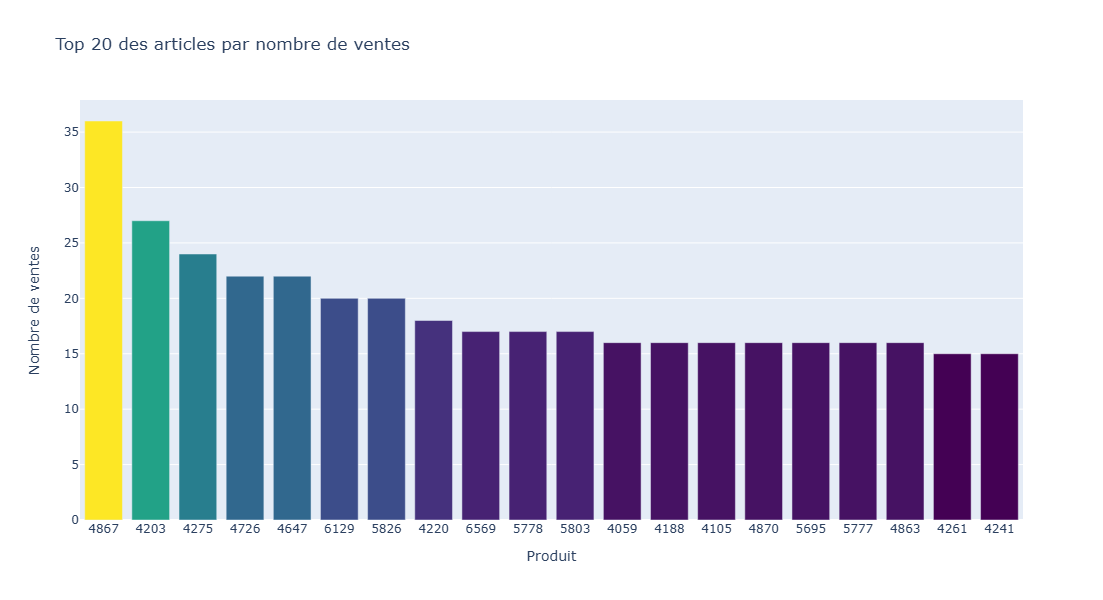

In [91]:
#####################################
# Palmares des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_final_décroissant_quantite = df_final.sort_values(by='total_sales', ascending=False)

#Réinitialiser l'index du dataset par un reset_index
df_final_reset_quantite = df_final_décroissant_quantite.reset_index(drop=True)

#Afficher les 20 premier articles en quantité
top_20_quantite = df_final_reset_quantite[['product_type','post_title','product_id', 'total_sales']].head(20)
print(top_20_quantite)

#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(top_20_quantite, 
             x='product_id', 
             y='total_sales', 
             title='Top 20 des articles par nombre de ventes',
             labels={'product_id': 'ID Produit', 'total_sales': 'Nombre de ventes'},
             color='total_sales', 
             color_continuous_scale='Viridis',
             hover_data=['post_title'])

fig.update_traces(
    hovertemplate="<b>ID Produit</b>: %{x}<br>" +
                  "<b>Nom de l'article</b>: %{customdata[0]}<extra></extra><br>" +
                  "<b>Nombre de ventes</b>: %{y:.f}<br>",
    customdata=top_20_CA[['post_title']] 
)
# Afficher le graphique
fig.update_layout(
    xaxis_title='Produit',
    yaxis_title='Nombre de ventes',
    height=600,
    coloraxis_showscale=False
)

fig.show()

In [92]:
###################################
# Calculer le 20 / 80 en quantité #
###################################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset
quantite_totale = df_final['total_sales'].sum()
df_final['proportion_ventes'] = (df_final['total_sales'] / quantite_totale) *100 # En %
print(df_final[['product_id', 'total_sales', 'proportion_ventes']].head())

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_final = df_final.sort_values(by='total_sales', ascending=False)
df_final['proportion_ventes_cum'] = df_final['proportion_ventes'].cumsum()
print(df_final[['product_id', 'total_sales', 'proportion_ventes', 'proportion_ventes_cum']].head())

#Grâce au deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
articles_80_quantite = df_final[df_final['proportion_ventes_cum'] <= 80]
nb_articles_80_quantite = articles_80_quantite.shape[0]
print(f"Nombre d'articles représentant 80% des ventes : {nb_articles_80_quantite}")

#Afficher la proportion que représentent ce groupe d'articles dans le catalogue entier du site web
nb_total_articles_quantite = df_final.shape[0]
proportion_articles_80_quantite = round((nb_articles_80_quantite / nb_total_articles_quantite) *100,2)
print(f"Proportion des articles responsables de 80% des ventes : {proportion_articles_80_quantite}%")

    product_id  total_sales  proportion_ventes
199       4352         11.0           0.191271
587       5892          6.0           0.104330
200       4353         14.0           0.243436
582       5826         20.0           0.347766
653       6212          7.0           0.121718
    product_id  total_sales  proportion_ventes  proportion_ventes_cum
365       4867         36.0           0.625978               0.625978
122       4203         27.0           0.469484               1.095462
175       4275         24.0           0.417319               1.512780
321       4726         22.0           0.382542               1.895323
265       4647         22.0           0.382542               2.277865
Nombre d'articles représentant 80% des ventes : 433
Proportion des articles responsables de 80% des ventes : 60.64%


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

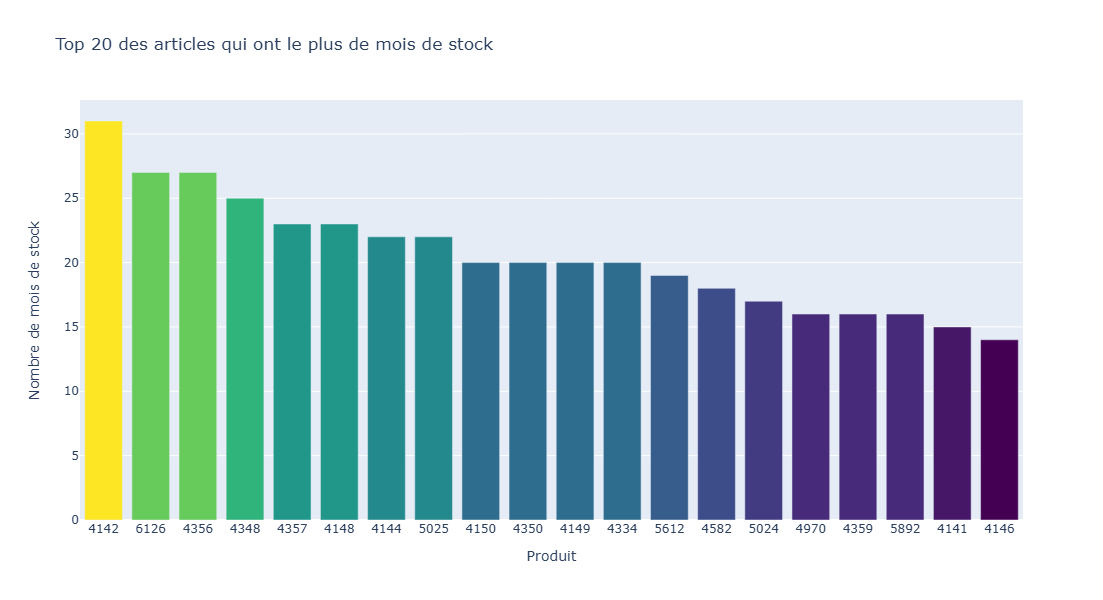

In [94]:
######################################
# Calcule le nombre de mois de stock #
######################################

#Création de la colonne Rotation de stock
df_final["Prévision_stock"] = (
    df_final["stock_quantity"] / df_final["total_sales"]
).replace([np.inf, -np.inf], np.nan).fillna(0).apply(np.floor).astype(int)

#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
df_final = df_final.sort_values(by='Prévision_stock', ascending=False)

#Graphique en barre du top 20 des produits qui ont le plus de mois de stock
top_20_prevision = df_final[['product_type','post_title','product_id', 'Prévision_stock']].head(20)
fig = px.bar(top_20_prevision, 
             x='product_id', 
             y='Prévision_stock', 
             title='Top 20 des articles qui ont le plus de mois de stock',
             labels={'product_id': 'ID Produit', 'Prévision_stock': 'Nombre de mois de stock'},
             color='Prévision_stock', 
             color_continuous_scale='Viridis',
             hover_data=['post_title'])

fig.update_traces(
    hovertemplate="<b>ID Produit</b>: %{x}<br>" +
                  "<b>Nom de l'article</b>: %{customdata[0]}<extra></extra><br>" +
                  "<b>Nombre de mois de stock</b>: %{y:.f}<br>",
    customdata=top_20_CA[['post_title']])
    
# Afficher le graphique
fig.update_layout(
    xaxis_title='Produit',
    yaxis_title='Nombre de mois de stock',
    height=600,
    coloraxis_showscale=False
)

fig.show()

In [95]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
df_final["Valorisation_stock_euros"] = df_final["stock_quantity"] * df_final["price"]

#Calculer la somme de la colonne "Valorisation_stock_euros"
total_valorisation = df_final["Valorisation_stock_euros"].sum()
print(f"Le stock total équivaut à {total_valorisation:.2f} €")

Le stock total équivaut à 494637.90 €


In [96]:
##############################################
# Valorisation du nombre de produit en stock #
##############################################

#Calculer la somme de la colonne stock quantity
stock_total = df_final['stock_quantity'].sum()
print(f"Le nombre de produits qui composent le stock est de {stock_total}")

Le nombre de produits qui composent le stock est de 16740


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [97]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne prix HT
df_final["Prix_HT"] = (df_final["price"] / 1.2).round(2)

#Création de la colonne Taux de marge
df_final["Prix_HT"] = df_final["Prix_HT"].astype(str).str.replace(",", ".").astype(float)
df_final["purchase_price"] = df_final["purchase_price"].astype(str).str.replace(",", ".").astype(float)

df_final["Taux_marge"] = (
    (df_final["Prix_HT"] - df_final["purchase_price"]) / df_final["Prix_HT"]
).replace([np.inf, -np.inf], np.nan).fillna(0).round(2) * 100

#Afficher le prix minimum de la colonne "taux_marge"
valeur_min_marge = df_final["Taux_marge"].min()
print(f"La valeur minimale du taux de marge est de {valeur_min_marge:.2f} %")

#Afficher le prix maximum de la colonne "taux_marge"
valeur_max_marge = df_final["Taux_marge"].max()
print(f"La valeur maximale du taux de marge est de {valeur_max_marge:.2f} %")

La valeur minimale du taux de marge est de -635.00 %
La valeur maximale du taux de marge est de 48.00 %


In [98]:
#affichage de la ligne avec un taux de marge inférieur à 0
ligne_min_taux_marge = df_final[df_final["Taux_marge"] == valeur_min_marge]
print(ligne_min_taux_marge)

    product_id  onsale_web  price  stock_quantity stock_status  \
201       4355           1  12.65              97      instock   

     purchase_price  stock_status_difference id_web    sku  total_sales  ...  \
201           77.48                        1  12589  12589          0.0  ...   

      z_score  ca_par_article part_CA part_CA_cum proportion_ventes  \
201 -0.713272             0.0     0.0       100.0               0.0   

    proportion_ventes_cum Prévision_stock Valorisation_stock_euros Prix_HT  \
201                 100.0               0                  1227.05   10.54   

    Taux_marge  
201     -635.0  

[1 rows x 35 columns]


In [99]:
#création d'un dataframe avec les taux positifs
df_taux_marge_positifs = df_final[df_final["Taux_marge"] >= 0]

#Afficher le prix minimum de la colonne "taux_marge"
valeur_min_marge_pos = df_taux_marge_positifs["Taux_marge"].min()
print(f"La valeur minimale du taux de marge est de {valeur_min_marge_pos:.2f} %")

#Afficher le prix maximum de la colonne "taux_marge"
valeur_max_marge_pos = df_taux_marge_positifs["Taux_marge"].max()
print(f"La valeur maximale du taux de marge est de {valeur_max_marge_pos:.2f} %")

La valeur minimale du taux de marge est de 23.00 %
La valeur maximale du taux de marge est de 48.00 %


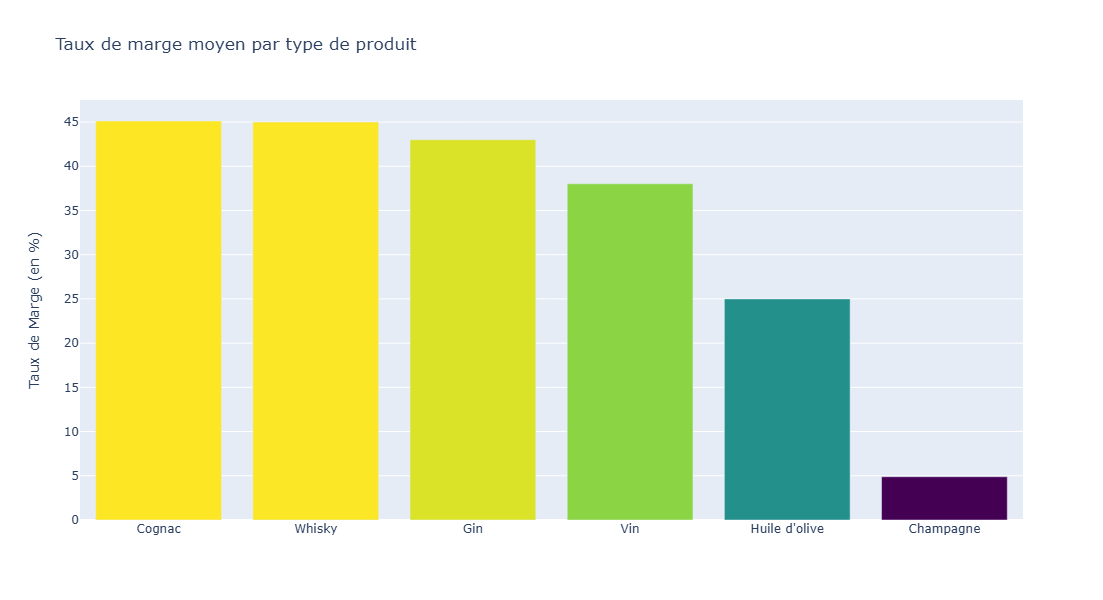

In [100]:
#Affichage dans un graphique du taux de marge par type de produit

# Calculer le taux de marge moyen par type de produit
taux_marge_par_type = df_final.groupby("product_type")["Taux_marge"].mean().reset_index()
taux_marge_par_type["Taux_marge"] = taux_marge_par_type["Taux_marge"].round(2)

# Trier les valeurs de manière décroissante par taux de marge
taux_marge_par_type = taux_marge_par_type.sort_values(by="Taux_marge", ascending=False)

# Créer un graphique en barres sans colorbar
fig = px.bar(taux_marge_par_type, 
             x="product_type", 
             y="Taux_marge", 
             title="Taux de marge moyen par type de produit",
             labels={'product_type': 'Type de Produit', 'Taux_marge': 'Taux de Marge (en %)'},
             color='Taux_marge',  # On garde la couleur mais sans colorbar
             color_continuous_scale='Viridis')

# Supprimer la colorbar
fig.update_layout(coloraxis_showscale=False)

# Afficher le graphique
fig.update_layout(
    xaxis_title='',
    yaxis_title='Taux de Marge (en %)',
    height=600
)

fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des correlations entre les variables stock, sales et price</h3>
</div>

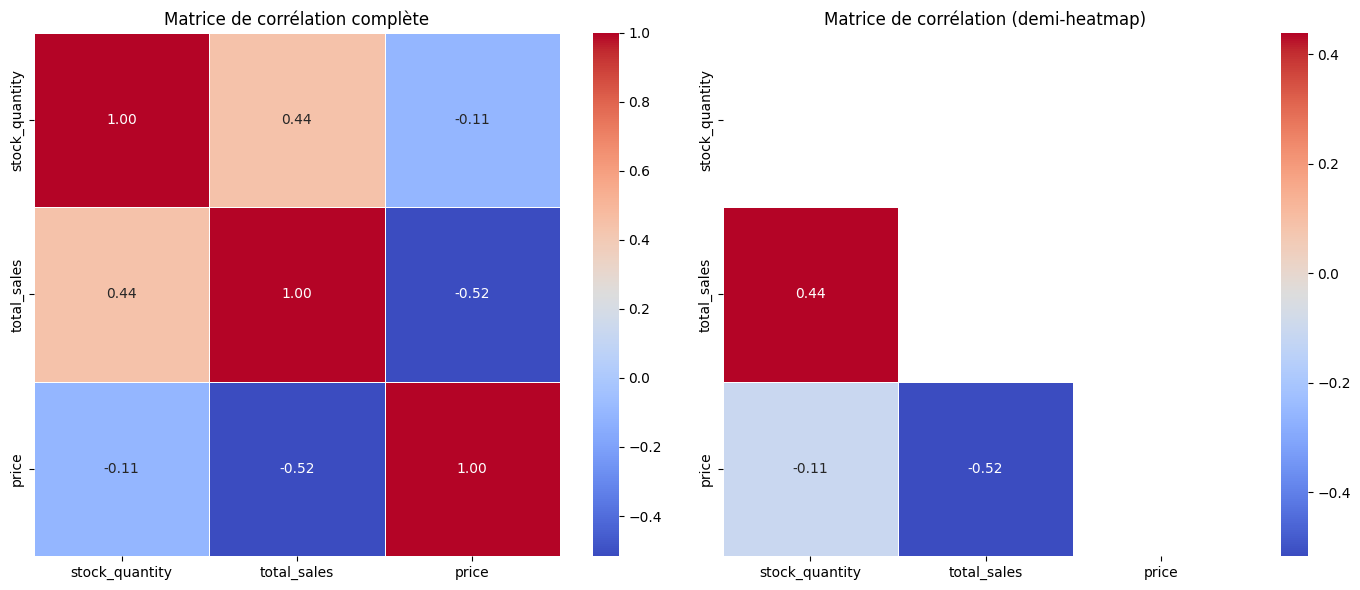

In [101]:
############################
# Analyse des correlations #
############################

#Importation de Seaborn
import seaborn as sns

#Création d'un heatmap de correlation avec les variables stock, sales et price #on peut également créer un mask pour n'afficher qu'une demi heatmap

# Sélectionner les variables
data_corr = df_final[["stock_quantity", "total_sales", "price"]]

# Calculer la matrice de corrélation
corr_matrix = data_corr.corr()

# Masquer la partie supérieure de la matrice pour la demi-heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Créer les subplots (1 ligne, 2 colonnes)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Créer la heatmap complète
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[0])
axes[0].set_title("Matrice de corrélation complète")

# Créer la demi-heatmap (partie inférieure)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, mask=mask, ax=axes[1])
axes[1].set_title("Matrice de corrélation (demi-heatmap)")

# Afficher les graphiques
plt.tight_layout()
plt.show()

In [102]:
#Que peut-on conclure des correlations ?

Corrélation entre total_sales et stock_quantity : 0.44 -> corrélation positive modérée entre la quantité de stock et les ventes. Lorsque le stock du produit augmente, les ventes du produit augmente également de façon générale

Corrélation entre total_sales et price : -0.52 -> corrélation négative modérée entre les ventes et le prix. Lorsque le prix du produit augmente, les ventes ont tendance à diminuer. Relation assez forte entre les deux variables.

Corrélation entre stock_quantity et price : -0.11 -> corrélation très faible et négative entre la quantité de stock et le prix. Quasiment pas de relation entre les deux variables.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mettre à disposition la nouvelle table sur un fichier Excel</h3>
</div>

In [103]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut-être utile pour partager le résultat du dataset obtenu pour le partager avec les équipes.  
df_final.to_excel("df_final_export.xlsx", index=False)